# M1 + M5 — 04 EDA / 探索分析

Descriptive April 2023 snapshot only. All retained rows are shown, including flagged observations. No causal annual depreciation/retention claim. Whole-cohort EDA includes held-out rows; no predictive test score is used for method selection.

In [1]:
from pathlib import Path
import sys,pandas as pd
ROOT=next(p for p in [Path.cwd(),Path.cwd().parent,Path.cwd()/'M1_EV_Deliverables'] if (p/'data/clean/ev_listings_clean_v2.csv').exists())
sys.path.insert(0,str(ROOT/'scripts'))
from m1_eda import create_eda
ev=pd.read_csv(ROOT/'data/clean/ev_listings_clean_v2.csv')
takeaways=create_eda(ev,ROOT)
print('Listings:',len(ev),'brands:',ev.manufacturer.nunique(),'model families:',ev.model_line.nunique())
print(ev.describe().to_string())


Saved 7 requested EDA figures
Listings: 15155 brands: 19 model families: 44
       listing_id          year        mileage  accidents_or_damage     one_owner  personal_use_only  seller_rating  driver_rating  driver_reviews_num    price_drop          price  source_excel_row  model_line_review_flag           age  miles_per_year  high_mileage_flag  premium_brand_flag  price_drop_raw  price_drop_was_missing  initial_price  price_cut_flag     log_price  very_low_mileage_flag  low_mileage_for_age_flag  near_new_flag  clean_history_flag  condition_score  battery_wear_proxy  bev_status_review_flag  iqr_reference_n   iqr_outlier   iso_outlier  iso_anomaly_score  confirmed_error_flag
count   15155.000  15155.000000   15149.000000         14344.000000  14180.000000       14342.000000   11616.000000   13525.000000        15155.000000  15155.000000   15155.000000      15155.000000            15155.000000  15155.000000    15149.000000       15149.000000        15155.000000     9541.000000           

## 1. Price before and after taking the log

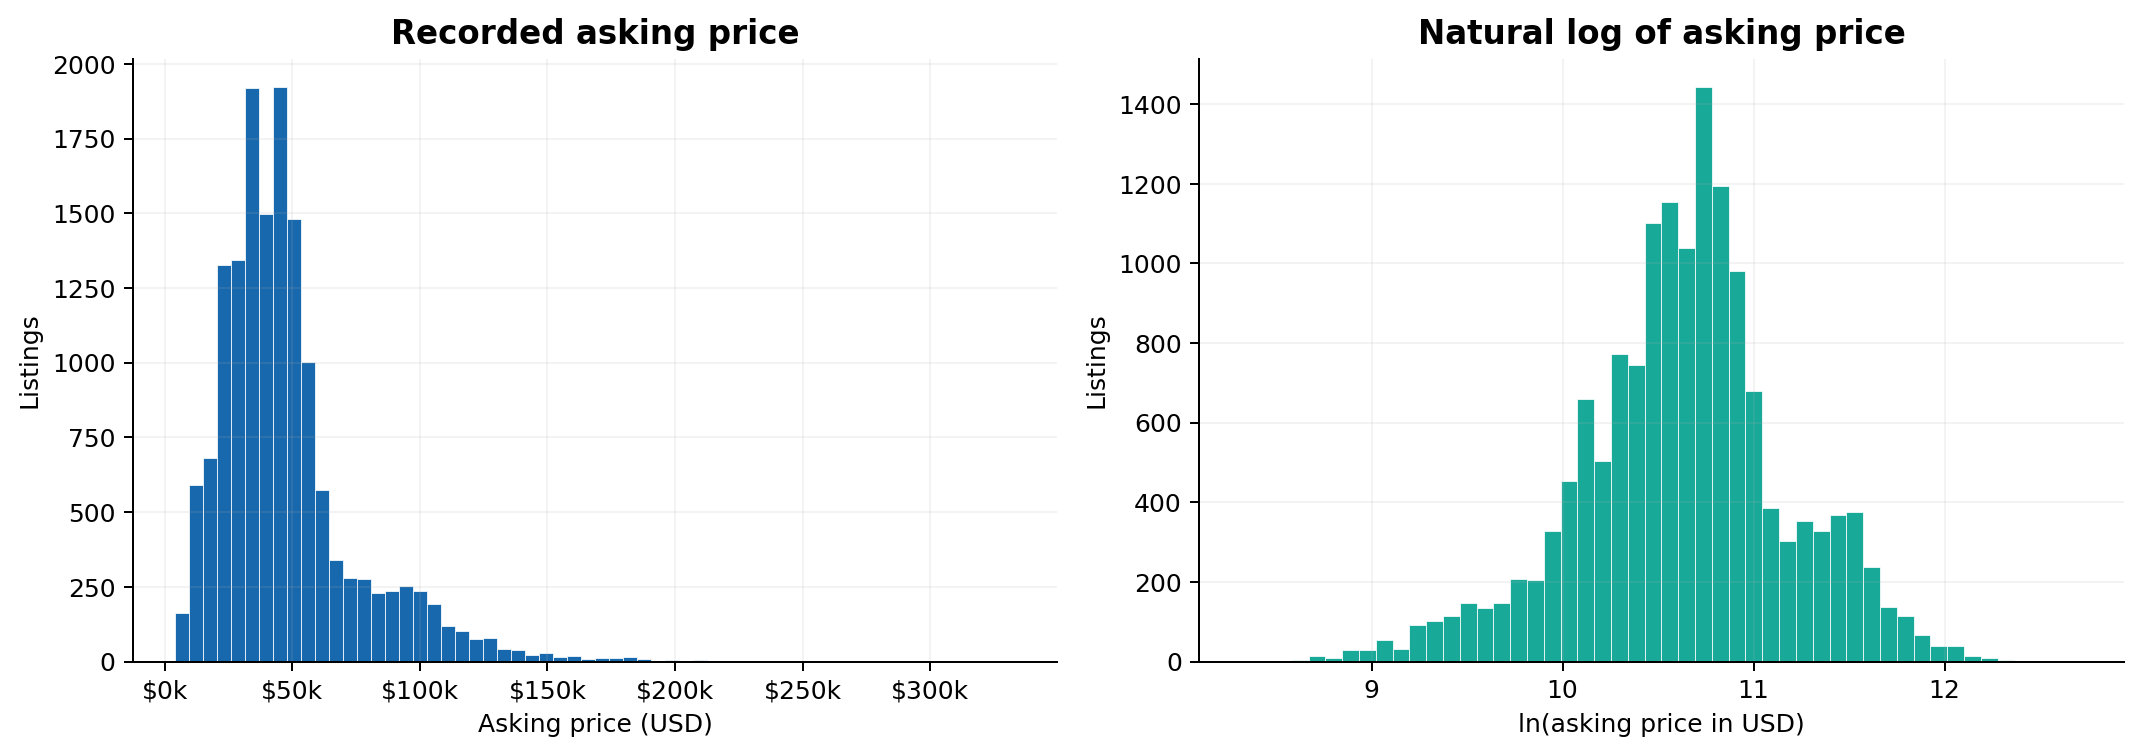

**Takeaway:** Raw-price skewness is 1.75; log-price skewness is -0.25. Log transformation reduces the high-price tail, but does not itself prove better predictive accuracy. All 15,155 listings, including the project-designated error, are shown.

**中文：** 原价偏度为 1.75，取对数后为 -0.25。高价尾部缩短，但是否提高预测精度仍需模型验证。图中保留全部 15,155 条记录。

## 2. Median price by age, top six model families

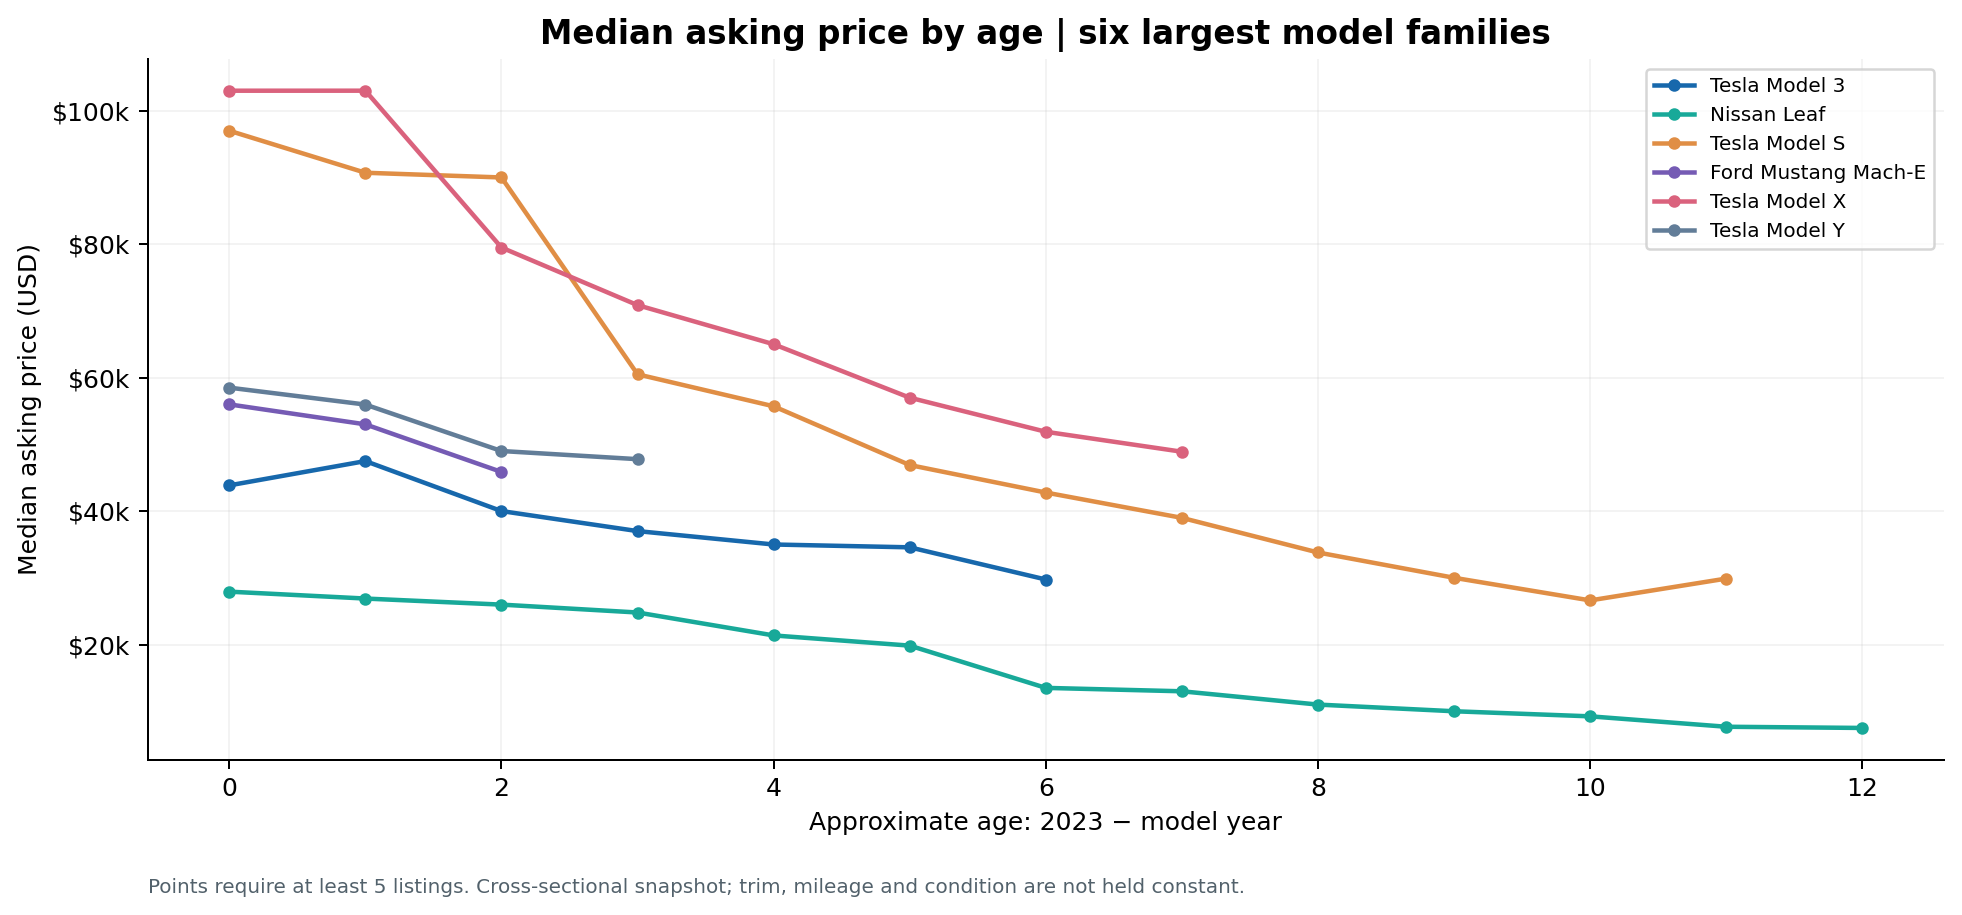

**Takeaway:** Prices vary substantially by model family and age. These are comparisons of different cars in April 2023, not measurements of how one car loses value each year. Sparse points with fewer than five listings are omitted.

**中文：** 不同车型、车龄对应的价格差别较大。这是同一时点不同车辆的对比，不能直接当成一辆车每年的贬值率。少于5辆的点不画。

## 3. Price versus mileage, coloured by brand

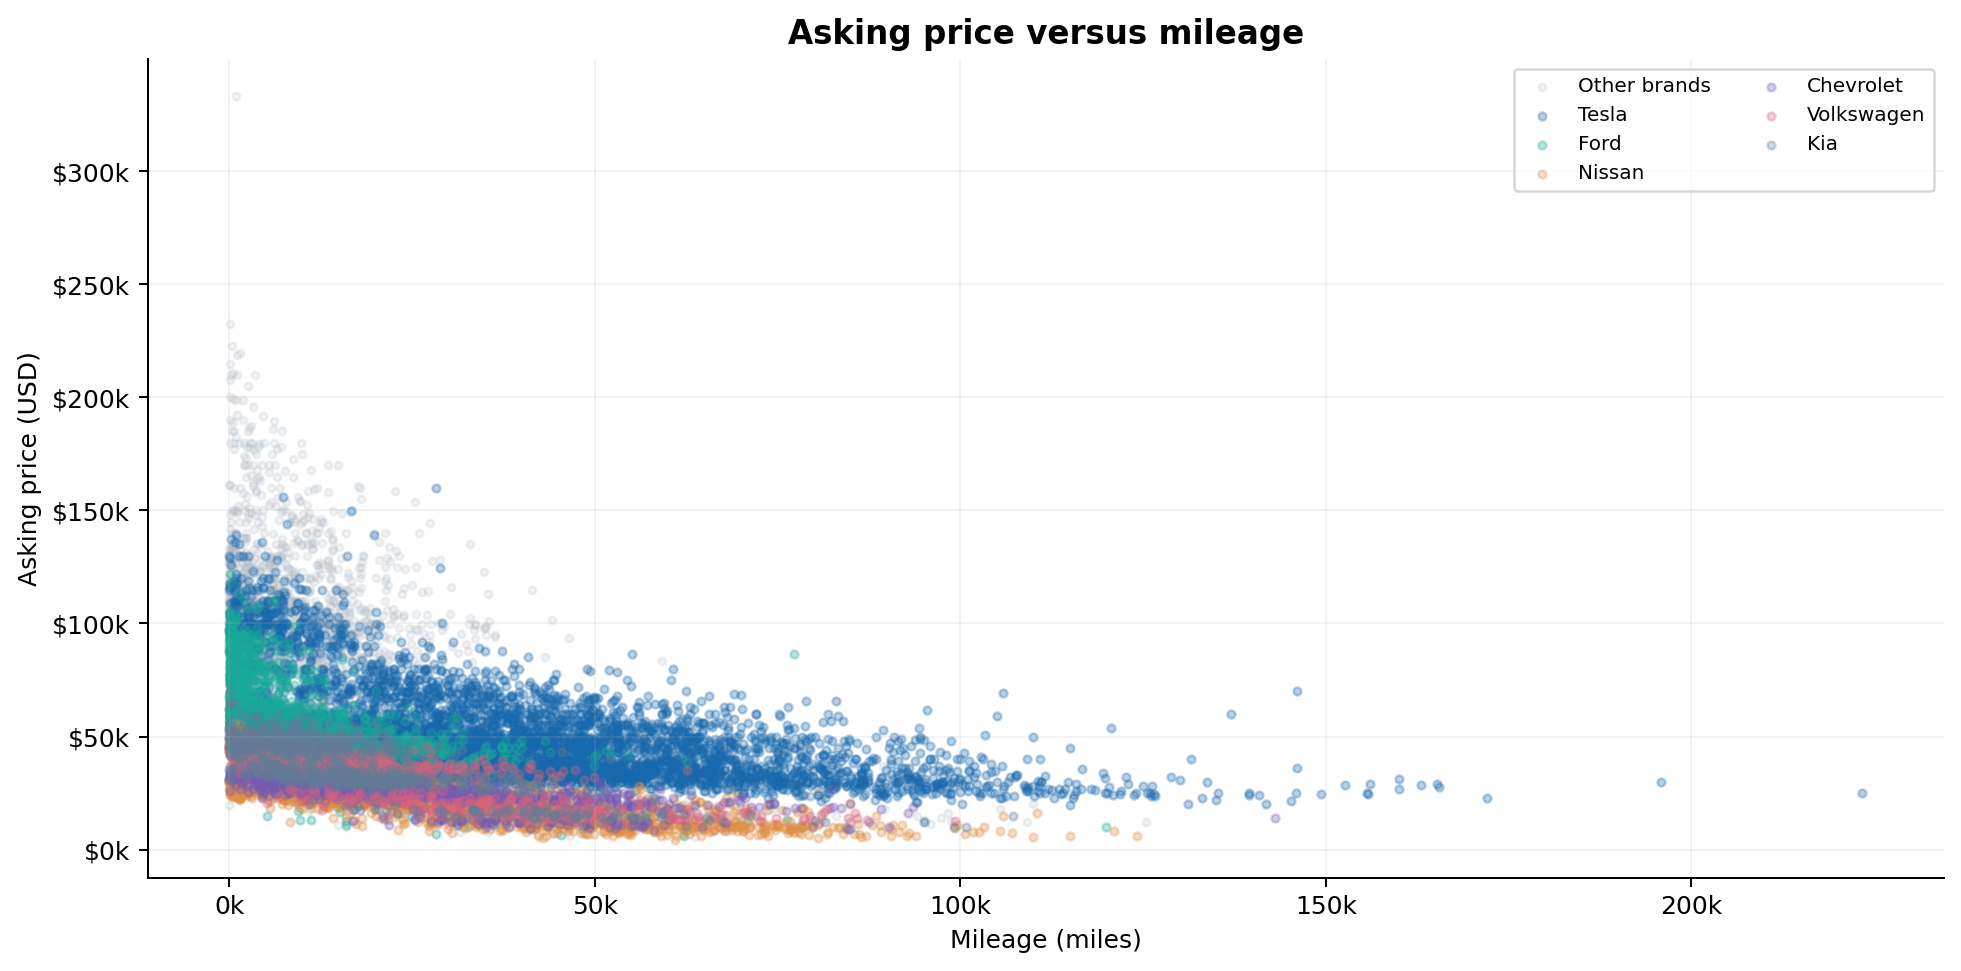

**Takeaway:** The pooled price–mileage rank correlation is -0.49. Brand and model differences remain visible, so this pooled association should not be interpreted as a mileage-only price effect.

**中文：** 价格与里程的整体秩相关系数为 -0.49。品牌和车型差异也明显，不能把整体关系理解为仅由里程造成的价格变化。

## 4. Accident versus no accident recorded

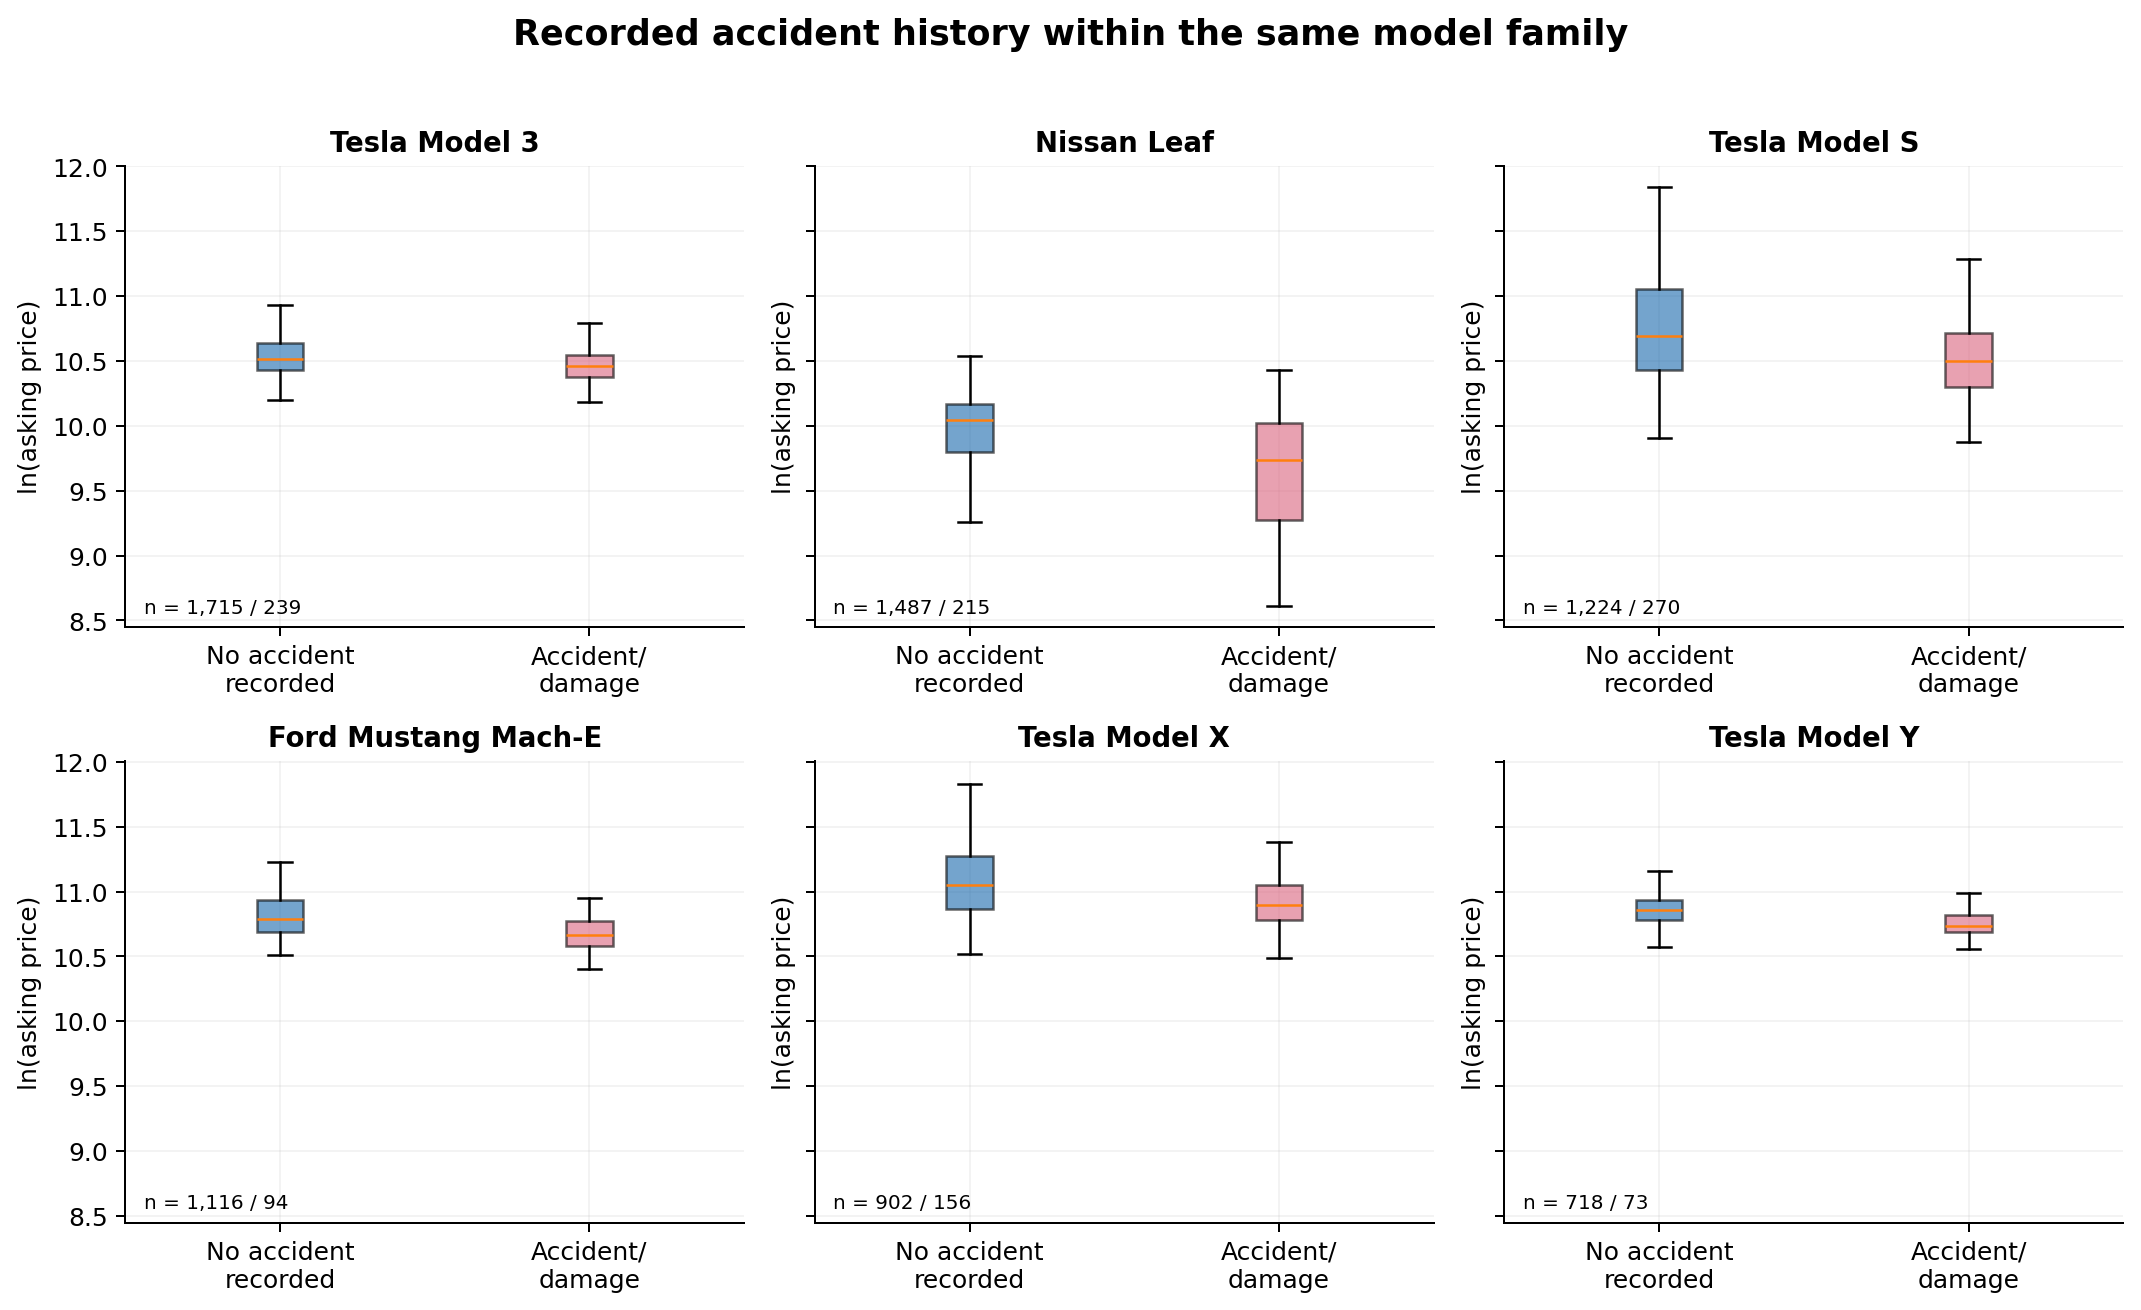

**Takeaway:** Compare accident histories within model families rather than across all brands. Age, mileage, trim and damage severity remain uncontrolled; unknown histories are excluded, and boxplot fliers are hidden only for readability.

**中文：** 先在相同车型内比较事故记录。车龄、里程、配置和事故程度仍未控制；未知事故记录不纳入两组，箱线图仅为易读而隐藏散点。

## 5. Median price and listing count by brand

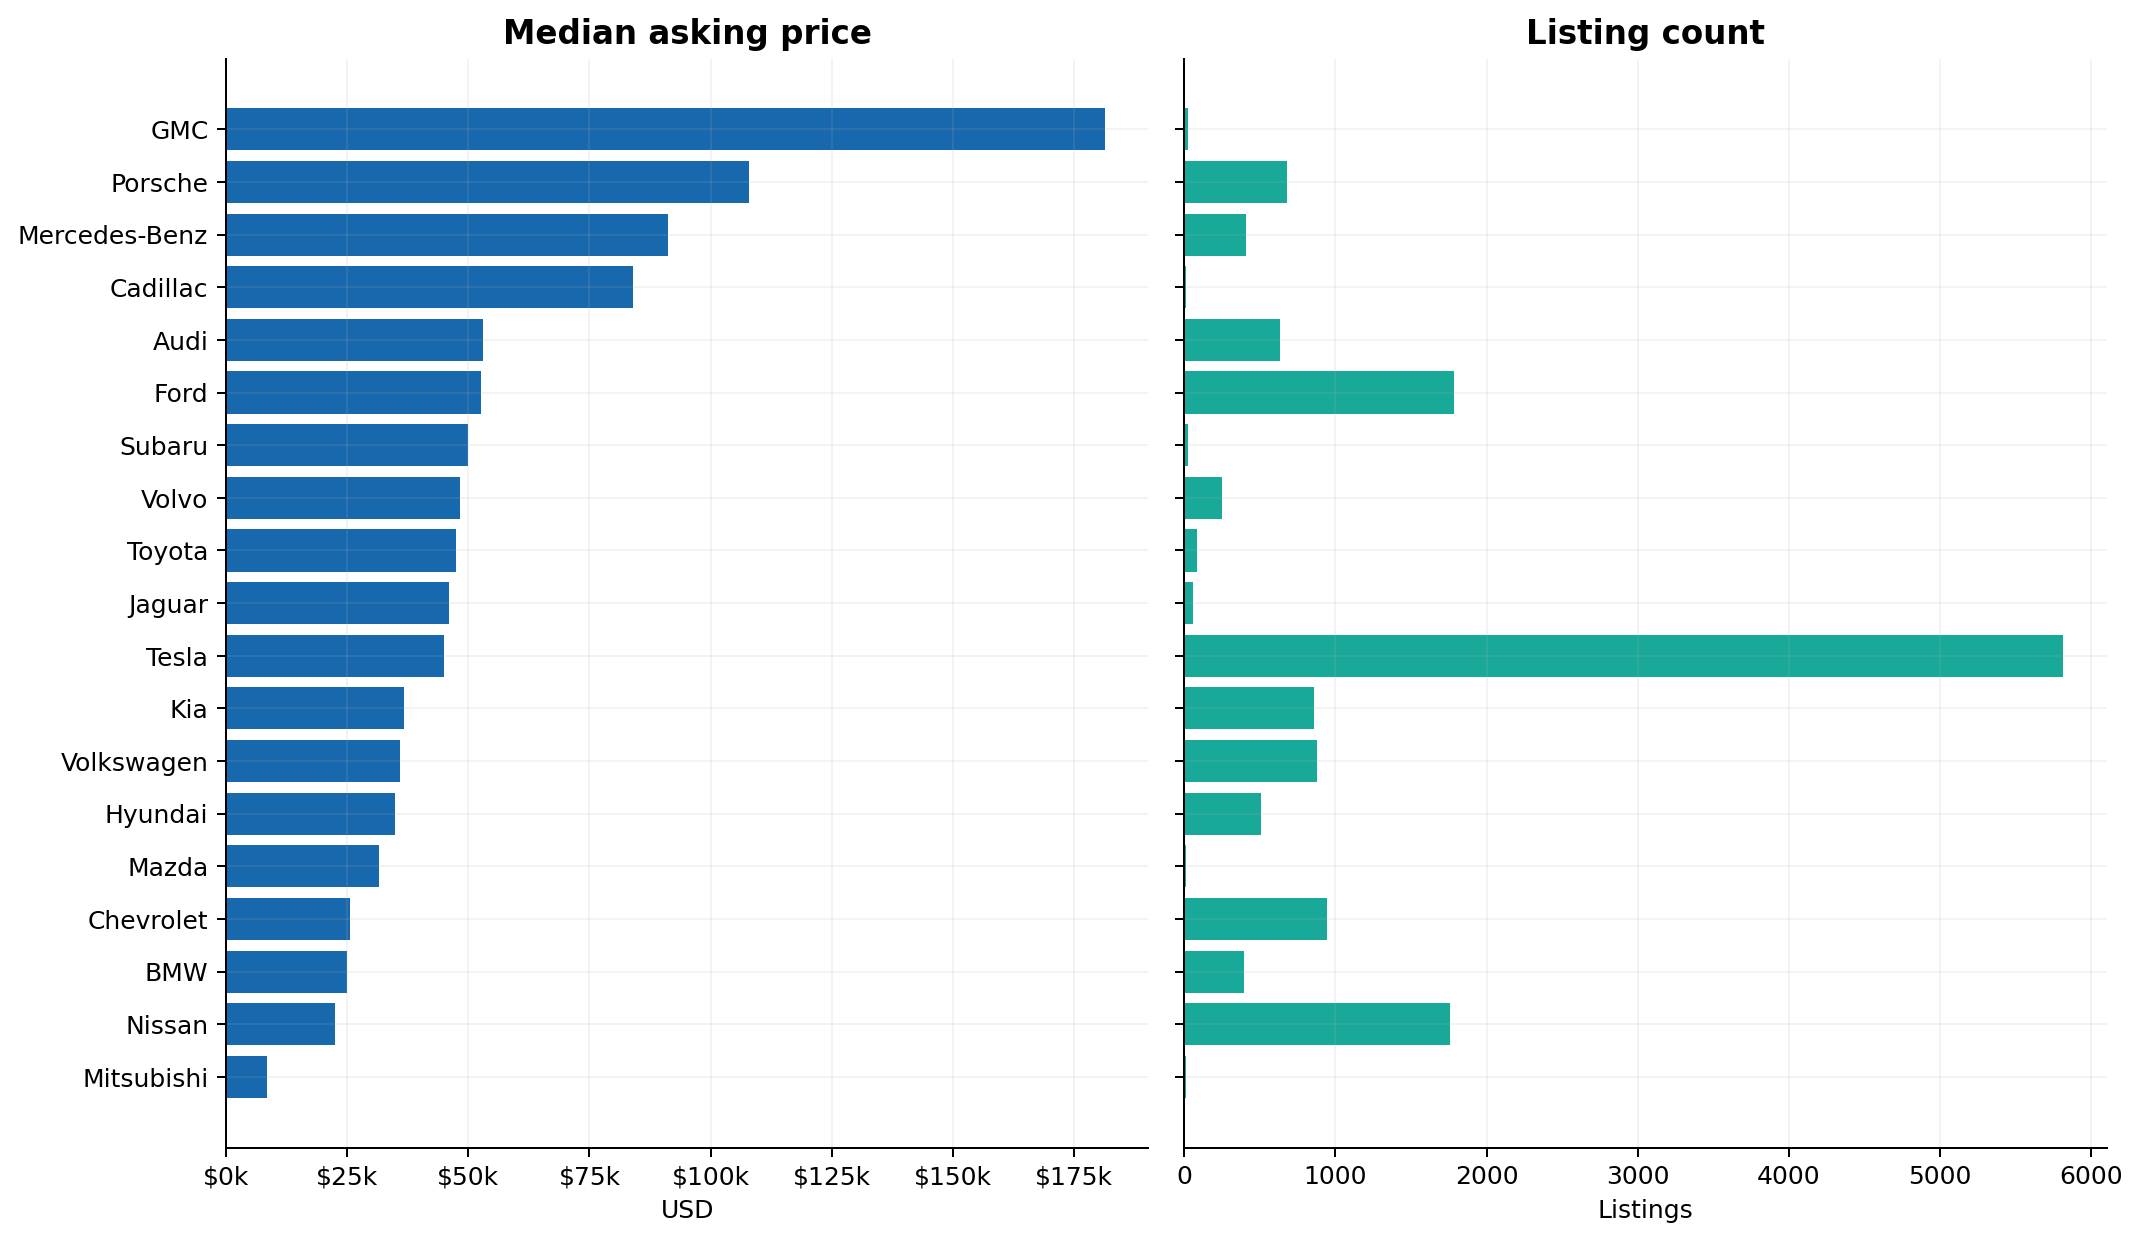

**Takeaway:** Tesla accounts for 5,812 listings (38.4% of the cohort). Brand median prices also reflect differences in model mix, age and mileage; they are not rankings of resale-value retention.

**中文：** Tesla 有 5,812 条，占样本 38.4%。品牌中位价格也受车型、车龄和里程组成影响，不是保值率排名。

## 6. Share of listings with a recorded price cut

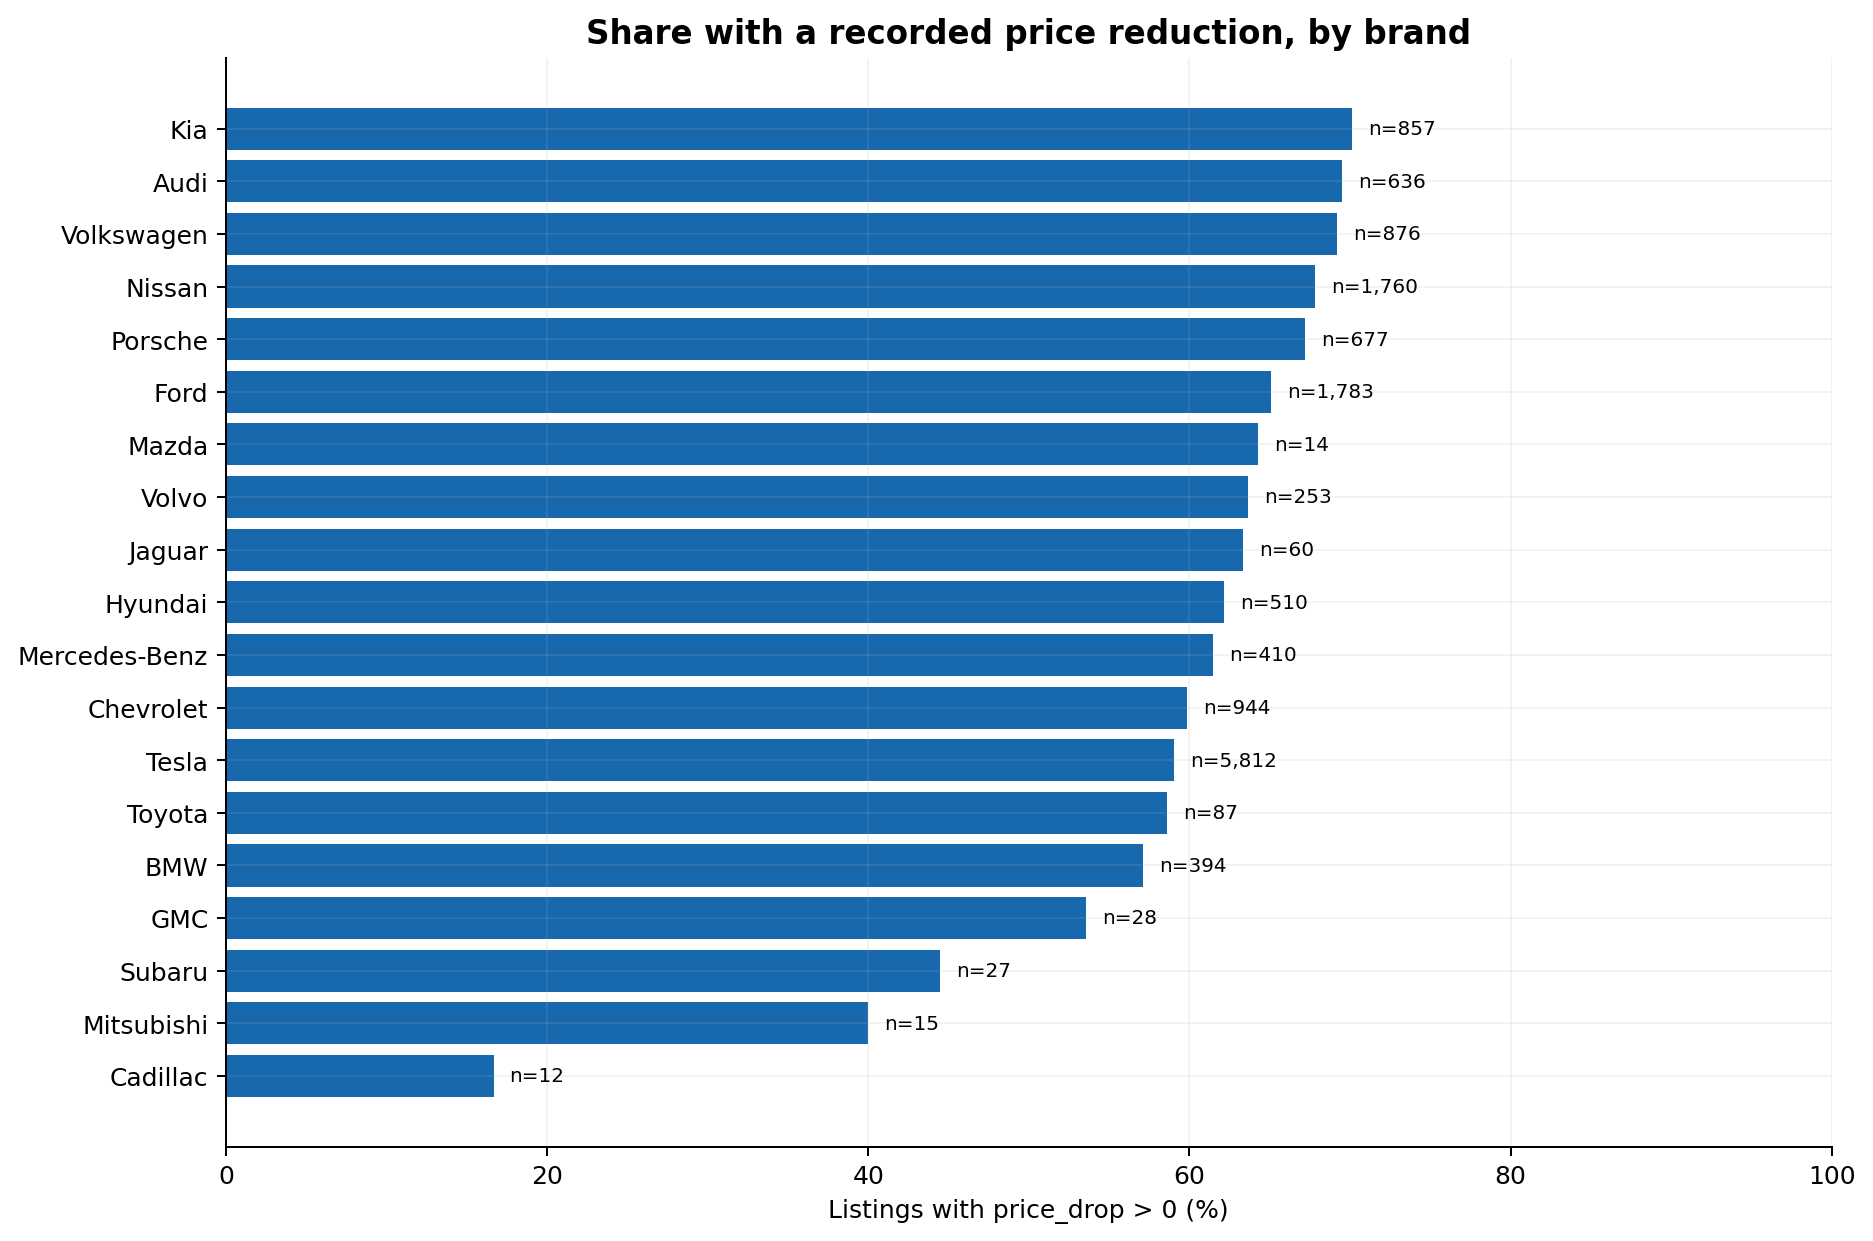

**Takeaway:** 63.0% of listings have a positive recorded price reduction. Missing price_drop values are treated as zero under the project assumption; this is neither a forecast of future cuts nor proof that a dealer originally overpriced a car.

**中文：** 63.0% 的记录有降价金额。按项目假设将缺失金额视为0；这既不是未来降价预测，也不能证明经销商一开始定价过高。

## 7. Summary statistics

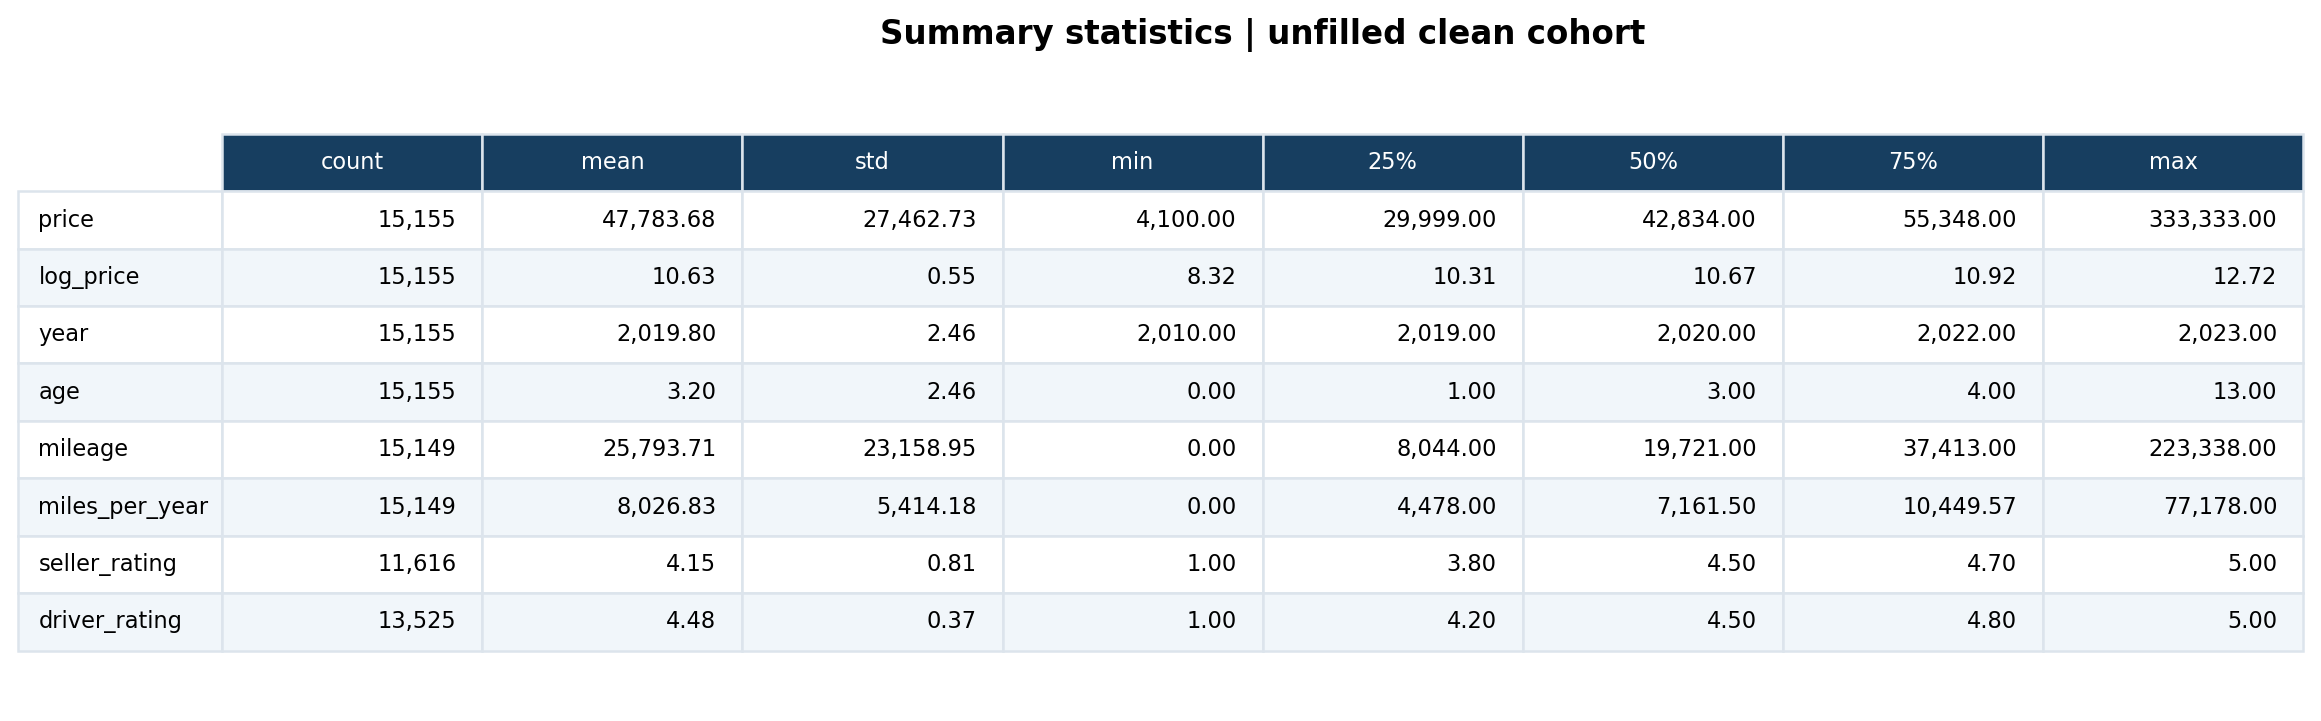

**Takeaway:** The cohort contains 15,155 listings. Median asking price is $42,834; median mileage is 19,721 miles. Missing values remain missing, and unusual observations remain in the handover.

**中文：** 样本共 15,155 条，中位挂牌价 $42,834，中位里程 19,721 英里。交接数据保留缺失和异常记录。